# 🟠 3. Deep Dive: Activations, Loss Functions & Optimizers

### *Mathematical Foundations, Analytical Derivatives, Loss Surfaces, Vanishing Gradients, and Optimizer Shootout*

---

## 📌 Module Overview
1. **Activation Functions**: Step, Sigmoid, Tanh, ReLU, Leaky ReLU, ELU, Softmax, Swish, and GELU.
2. **Vanishing Gradient & Dying ReLU Problems**: Mathematical cause and mitigation.
3. **Loss Functions**: MSE, MAE, Huber Loss (Regression); BCE, CCE, Sparse CCE (Classification).
4. **Why MSE Fails for Classification**: Derivation of non-convexity with Sigmoid.
5. **Optimization Algorithms**: Batch GD, SGD, Mini-Batch, Momentum, NAG, AdaGrad, RMSprop, Adam, and AdamW.
6. **Empirical Shootout**: Comparative non-convex convergence curves.


In [1]:
import numpy as np
import matplotlib.pyplot as plt
import warnings
warnings.filterwarnings('ignore')

plt.style.use('seaborn-v0_8-whitegrid' if 'seaborn-v0_8-whitegrid' in plt.style.available else 'default')
plt.rcParams['figure.figsize'] = (10, 5)
plt.rcParams['axes.titlesize'] = 13
plt.rcParams['axes.titleweight'] = 'bold'
SEED = 42
np.random.seed(SEED)
print("Deep Dive environment ready.")


Deep Dive environment ready.


## 1. Activation Functions & Analytical Derivatives
* **Sigmoid**: $\sigma(z) = \frac{1}{1 + e^{-z}}$, derivative $\sigma'(z) = \sigma(z)(1 - \sigma(z))$. Maximum derivative is $0.25$ at $z=0$.
* **Tanh**: $\tanh(z) = \frac{e^z - e^{-z}}{e^z + e^{-z}}$, derivative $1 - \tanh^2(z)$. Zero-centered.
* **ReLU**: $\max(0, z)$, derivative $1 \text{ if } z > 0 \text{ else } 0$. Non-saturating for positive inputs.
* **Leaky ReLU**: $\max(\alpha z, z)$, fixes the Dying ReLU problem.
* **ELU**: $z \text{ if } z > 0 \text{ else } \alpha(e^z - 1)$. Smooth transition.
* **Swish / SiLU**: $z \cdot \sigma(z)$. Modern smooth non-monotonic activation.


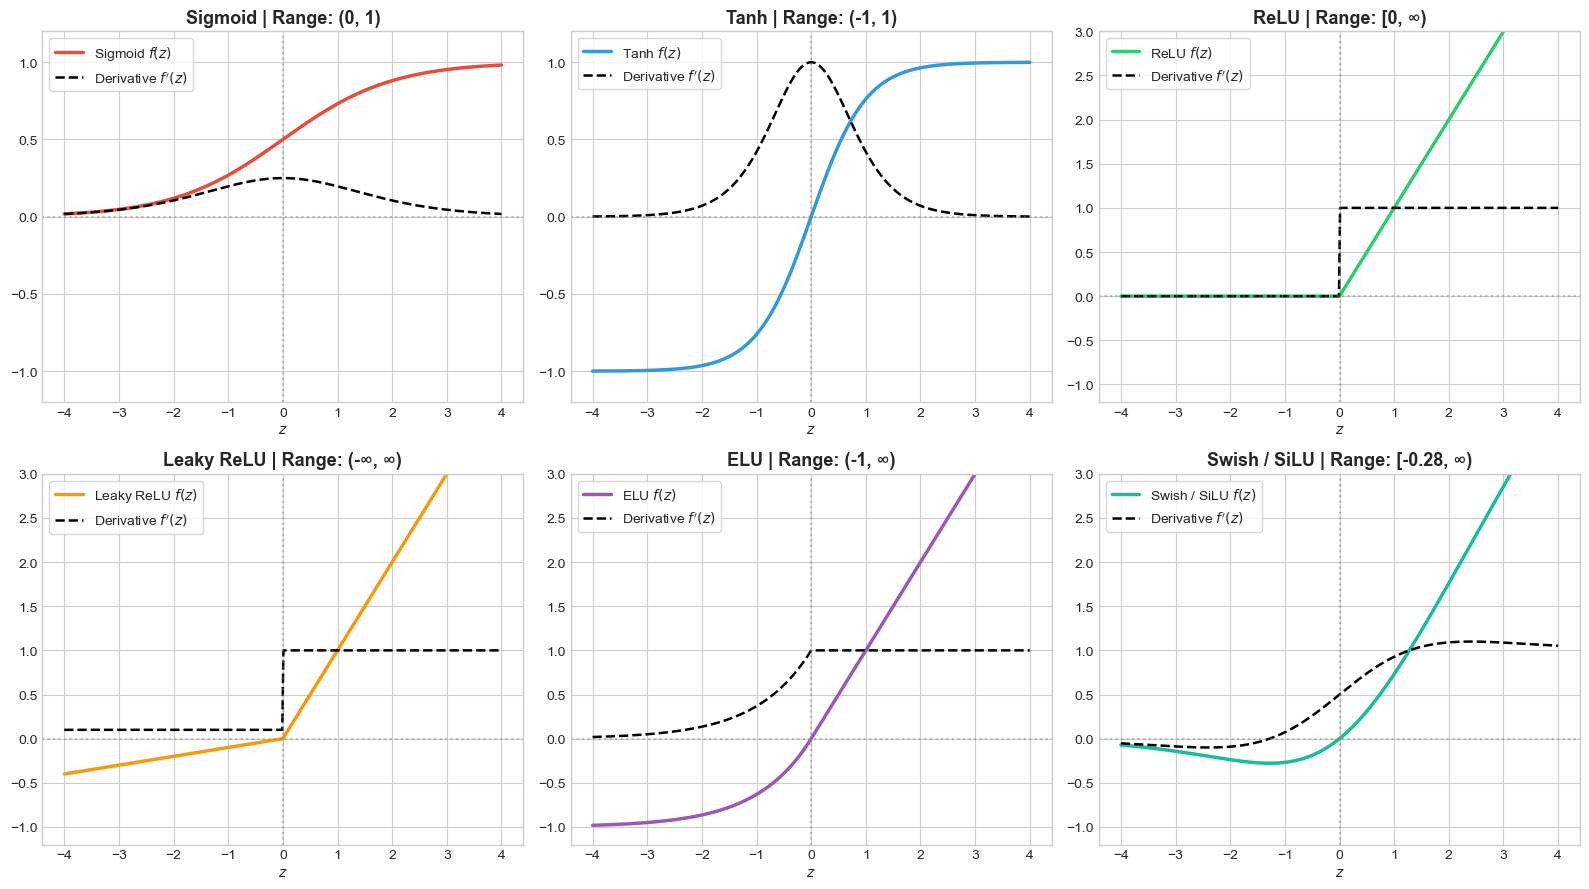

In [2]:
# Visualizing 6 Major Activation Functions and Their Exact Derivatives
z = np.linspace(-4.0, 4.0, 400)

def sig(x): return 1.0 / (1.0 + np.exp(-x))
def d_sig(x): s = sig(x); return s * (1.0 - s)

def th(x): return np.tanh(x)
def d_th(x): return 1.0 - np.tanh(x)**2

def rlu(x): return np.maximum(0, x)
def d_rlu(x): return np.where(x > 0, 1.0, 0.0)

def l_rlu(x, a=0.1): return np.where(x > 0, x, a * x)
def d_l_rlu(x, a=0.1): return np.where(x > 0, 1.0, a)

def elu_f(x, a=1.0): return np.where(x > 0, x, a * (np.exp(x) - 1.0))
def d_elu_f(x, a=1.0): return np.where(x > 0, 1.0, elu_f(x, a) + a)

def swish_f(x): return x * sig(x)
def d_swish_f(x): s = sig(x); return s + x * s * (1.0 - s)

fig, axes = plt.subplots(2, 3, figsize=(16, 9))
axes = axes.flatten()

data = [
    ("Sigmoid", sig(z), d_sig(z), "#e74c3c", "(0, 1)"),
    ("Tanh", th(z), d_th(z), "#3498db", "(-1, 1)"),
    ("ReLU", rlu(z), d_rlu(z), "#2ecc71", "[0, ∞)"),
    ("Leaky ReLU", l_rlu(z), d_l_rlu(z), "#f39c12", "(-∞, ∞)"),
    ("ELU", elu_f(z), d_elu_f(z), "#9b59b6", "(-1, ∞)"),
    ("Swish / SiLU", swish_f(z), d_swish_f(z), "#1abc9c", "[-0.28, ∞)")
]

for idx, (name, val, d_val, col, rng) in enumerate(data):
    ax = axes[idx]
    ax.plot(z, val, label=f'{name} $f(z)$', color=col, linewidth=2.5)
    ax.plot(z, d_val, label="Derivative $f'(z)$", color='black', linestyle='--', linewidth=1.8)
    ax.axhline(0, color='gray', linestyle=':', alpha=0.5)
    ax.axvline(0, color='gray', linestyle=':', alpha=0.5)
    ax.set_title(f"{name} | Range: {rng}")
    ax.set_xlabel('$z$')
    ax.legend(loc='upper left', frameon=True)
    ax.set_ylim(-1.2, 3.0 if 'ReLU' in name or 'Swish' in name or 'ELU' in name else 1.2)

plt.tight_layout()
plt.show()


## 2. Loss Functions: Regression vs. Classification
* **MSE vs. MAE vs. Huber**: MSE heavily penalizes large outliers; MAE is robust but non-smooth at 0; Huber combines both.
* **Binary Cross-Entropy (BCE)**:
  $$\mathcal{L}(y, \hat{y}) = -[y \ln \hat{y} + (1-y)\ln(1 - \hat{y})]$$
* **Why NOT MSE for Classification?** Pairing MSE with Sigmoid creates flat gradient plateaus where the derivative $\sigma'(z) \to 0$, causing training to freeze. Cross-entropy cancels out $\sigma'$, yielding the clean linear gradient $(\hat{y} - y)$.


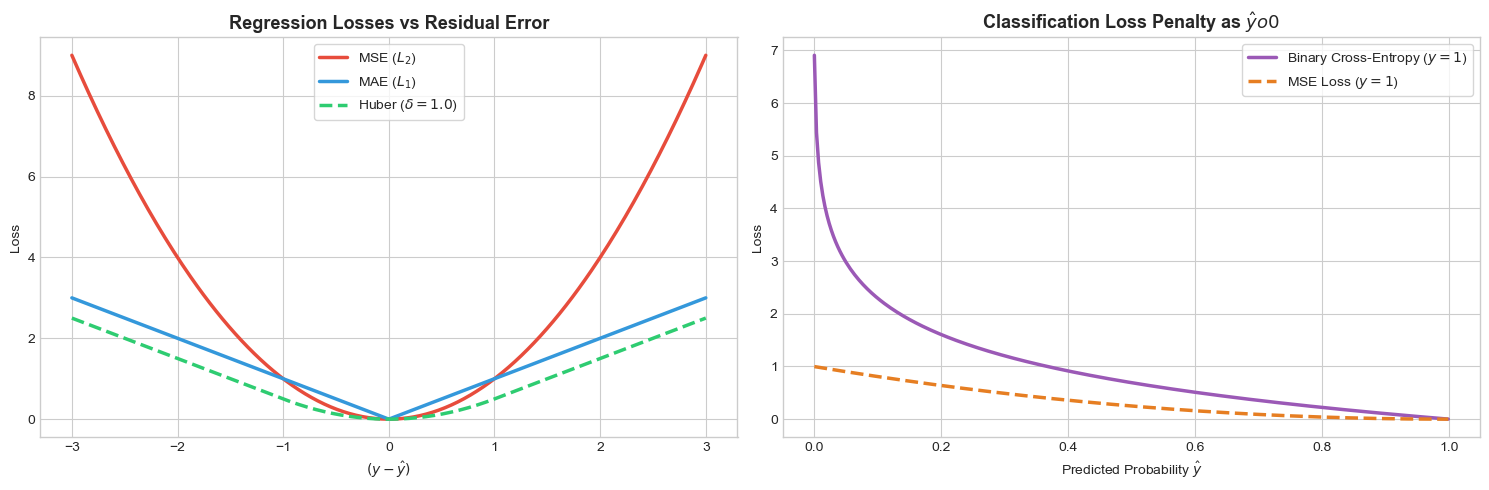

In [3]:
# Visualizing Loss Behaviors
err = np.linspace(-3, 3, 300)
mse = err ** 2
mae = np.abs(err)
huber = np.where(np.abs(err) <= 1.0, 0.5 * err**2, 1.0 * np.abs(err) - 0.5)

p = np.linspace(0.001, 0.999, 300)
bce_1 = -np.log(p)
mse_1 = (1.0 - p)**2

fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(15, 5))
ax1.plot(err, mse, label='MSE ($L_2$)', color='#e74c3c', linewidth=2.5)
ax1.plot(err, mae, label='MAE ($L_1$)', color='#3498db', linewidth=2.5)
ax1.plot(err, huber, label='Huber ($\delta=1.0$)', color='#2ecc71', linestyle='--', linewidth=2.5)
ax1.set_title('Regression Losses vs Residual Error')
ax1.set_xlabel('$(y - \hat{y})$')
ax1.set_ylabel('Loss')
ax1.legend(frameon=True)

ax2.plot(p, bce_1, label='Binary Cross-Entropy ($y=1$)', color='#9b59b6', linewidth=2.5)
ax2.plot(p, mse_1, label='MSE Loss ($y=1$)', color='#e67e22', linestyle='--', linewidth=2.5)
ax2.set_title('Classification Loss Penalty as $\hat{y} 	o 0$')
ax2.set_xlabel('Predicted Probability $\hat{y}$')
ax2.set_ylabel('Loss')
ax2.legend(frameon=True)

plt.tight_layout()
plt.show()


## 3. Optimizers Shootout on a Non-Convex Objective
We test **Vanilla SGD**, **SGD + Momentum**, **RMSprop**, and **Adam** on Beale's non-convex test surface to observe convergence speeds and saddle point escape dynamics.


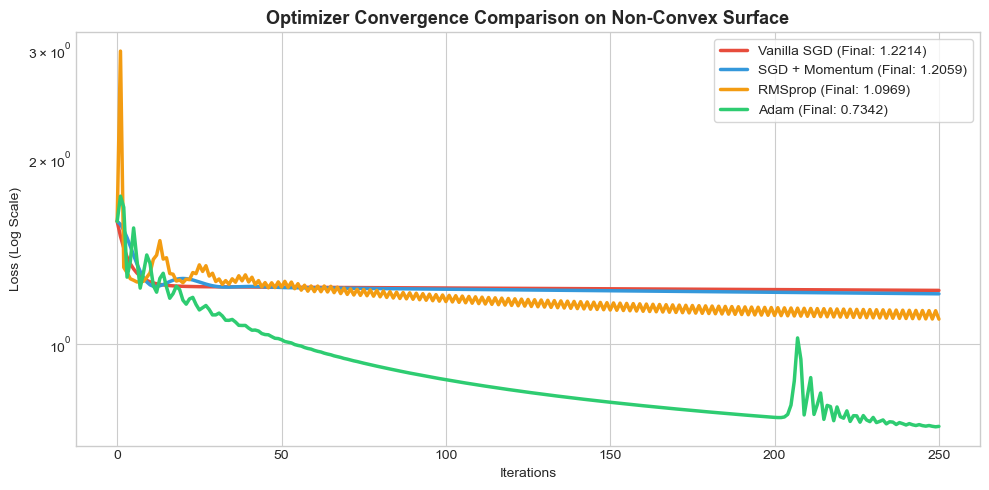

In [4]:
def beale(x, y):
    return (1.5 - x + x*y)**2 + (2.25 - x + x*y**2)**2 + (2.625 - x + x*y**3)**2

def grad_beale(x, y):
    df_dx = (2*(1.5 - x + x*y)*(-1 + y) + 2*(2.25 - x + x*y**2)*(-1 + y**2) + 2*(2.625 - x + x*y**3)*(-1 + y**3))
    df_dy = (2*(1.5 - x + x*y)*x + 2*(2.25 - x + x*y**2)*(2*x*y) + 2*(2.625 - x + x*y**3)*(3*x*y**2))
    return np.array([df_dx, df_dy])

def run_opt(name, lr=0.01, epochs=250):
    pos = np.array([-1.5, 1.5], dtype=float)
    losses = [beale(pos[0], pos[1])]
    v, s = np.zeros(2), np.zeros(2)

    for t in range(1, epochs + 1):
        g = np.clip(grad_beale(pos[0], pos[1]), -50, 50)
        if name == 'Vanilla SGD':
            pos -= lr * g
        elif name == 'SGD + Momentum':
            v = 0.9 * v + 0.1 * g
            pos -= lr * v
        elif name == 'RMSprop':
            s = 0.9 * s + 0.1 * (g ** 2)
            pos -= (lr / (np.sqrt(s) + 1e-8)) * g
        elif name == 'Adam':
            v = 0.9 * v + 0.1 * g
            s = 0.999 * s + 0.001 * (g ** 2)
            v_hat = v / (1 - 0.9 ** t)
            s_hat = s / (1 - 0.999 ** t)
            pos -= (lr / (np.sqrt(s_hat) + 1e-8)) * v_hat
        losses.append(beale(pos[0], pos[1]))
    return losses

opts = [
    ('Vanilla SGD', 0.0005, '#e74c3c'),
    ('SGD + Momentum', 0.001, '#3498db'),
    ('RMSprop', 0.05, '#f39c12'),
    ('Adam', 0.1, '#2ecc71')
]

plt.figure(figsize=(10, 5))
for name, lr, col in opts:
    l_hist = run_opt(name, lr=lr)
    plt.plot(l_hist, label=f"{name} (Final: {l_hist[-1]:.4f})", color=col, linewidth=2.5)

plt.yscale('log')
plt.title('Optimizer Convergence Comparison on Non-Convex Surface', fontweight='bold')
plt.xlabel('Iterations')
plt.ylabel('Loss (Log Scale)')
plt.legend(frameon=True)
plt.tight_layout()
plt.show()
